# VGG16_HD (LOCAL / VS Code version) - Hair Disease Classification (10 classes)

**Run the cells strictly from top to bottom, one at a time, and read each output before moving on.**

Pipeline follows the public repo *Visual-Recognition-of-Hair-Disorders* (VGG16 backbone, ImageNet weights,
GlobalAveragePooling -> Dense(512, ReLU) -> Dropout -> Softmax, 224x224 input, pixels scaled to [0,1],
rotation / shift / zoom / flip augmentation). Folder layout, data split and evaluation code are the same as
`InceptionV3_HD.ipynb`, so the results are directly comparable.

Differences from the repo (on purpose, for a rigorous thesis): validation-loss early stopping, a second
fine-tuning phase (last conv block `block5`), fixed seed, leakage check, test set used once, bootstrap CI.

| Part | Cells | What it produces |
|---|---|---|
| A. Setup | 1-5 | GPU check, Drive, config, seed + mixed precision, data copied to Colab disk |
| B. Data verification | 6-12 | Class counts, leakage check between splits, sample images |
| C. Model sanity checks | 13-16 | Proof that the model and pipeline work before real training |
| D. Training | 17-24 | Phase 1 (head only) and Phase 2 (fine-tune block5), curves, best checkpoint |
| E. Final test evaluation | 25-32 | Metrics, confusion matrix, 95% CI, error analysis (**run once**) |
| F. Save | 33 | Summary of the whole experiment |

Every run writes to its own folder `results/<RUN_NAME>/`, so nothing is overwritten.
To report mean +- std, repeat the whole notebook with `SEED = 42, 123, 2024`.

**Local version (Mac, TensorFlow 2.15 + tensorflow-metal):** set `DRIVE_DIR` in Cell 3 to your project folder. It must contain
`data_processed/dataset_224_v3.zip`. Results are written to `<DRIVE_DIR>/results/`. Mixed precision is turned off locally.

**Section G (end of this notebook) = 5-fold cross-validation.** It is self-contained: run Cells 1-5, then jump to Cell 34.

## A. Setup

### Cell 1 - Imports, library versions, device
Expected on a Mac with `tensorflow-metal`: `GPUs : [PhysicalDevice(name='/physical_device:GPU:0', ...)]`.
An empty list means CPU only (much slower).

In [14]:
import os, sys, json, time, random, zipfile, subprocess, platform, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
import sklearn
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             f1_score, cohen_kappa_score, roc_auc_score, classification_report,
                             confusion_matrix)
from PIL import Image

print("Python     :", platform.python_version())
print("TensorFlow :", tf.__version__)
print("Keras      :", keras.__version__)
print("NumPy      :", np.__version__)
print("scikit-learn:", sklearn.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("GPUs       :", gpus)
if not gpus:
    print("WARNING: no GPU found - training will run on the CPU and be very slow.")

Python     : 3.11.17
TensorFlow : 2.15.1
Keras      : 2.15.0
NumPy      : 1.26.4
scikit-learn: 1.9.1
GPUs       : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Cell 2 - (Colab only) Google Drive is not used in the local version
Nothing to do; just run the cell.

In [15]:
print("Local run: Google Drive is not used.")

Local run: Google Drive is not used.


### Cell 3 - Experiment configuration
**Edit `DRIVE_DIR` only** (your local project folder that contains `data_processed/` and `results/`).
All hyper-parameters live here, so they are recorded with the results.
Items marked `(assumed)` are not stated in the repo README; change them only before the first real run.
Note: VGG16 was originally trained with caffe-style preprocessing (BGR, mean subtraction). The repo's [0,1] scaling
uses the VGG16 ImageNet preprocessing (`PREPROCESS = "imagenet_vgg"`) so the pretrained backbone receives the input range it expects.

**`DATA_MODE`** chooses the data: `"subset"` = a random 5% of every class in every split (fast tests), `"rest"` = the other 95%,
`"full"` = the whole dataset (**use this for the final results**). The subset and the rest are created once, are disjoint,
and are saved as folders (and zips) in `data_processed/`, so every model is trained on exactly the same images.
Runs on the subset / rest get a `_sub5pct` / `_rest95pct` tag in their folder names.
Never report subset numbers as final results (the test part has only a handful of images per class).

In [16]:
# ------------------------------------------------------------- EDIT THIS LINE
DRIVE_DIR = "/Users/nngoc/Documents/Hair Diseases/Hair-Disease-Research"   # LOCAL project folder
# -------------------------------------------------------------------------

SEED = 42
ZIP_PATH = f"{DRIVE_DIR}/data_processed/dataset_224_v3.zip"
RESULTS_ROOT = f"{DRIVE_DIR}/results"
# --- Which data to use. "subset" = random 5% (fast tests) | "rest" = the other 95% | "full" = whole dataset (final results)
DATA_MODE = "subset"
SUBSET_FRACTION = 0.05       # fraction of EVERY class in each of train / val / test that goes to the subset
CREATE_REST_SPLIT = True     # also save the remaining 95% as its own dataset (disjoint from the subset)
ZIP_SUBSETS = True           # also write dataset_224_v3_sub5pct.zip / dataset_224_v3_rest95pct.zip (to move them to Colab / Kaggle)
SUB_PCT = round(SUBSET_FRACTION * 100); REST_PCT = 100 - SUB_PCT
assert DATA_MODE in ("subset", "rest", "full"), 'DATA_MODE must be "subset", "rest" or "full"'
FULL_DATA_DIR = f"{DRIVE_DIR}/data_processed/dataset_224_v3"      # unzipped next to the zip file
SUBSET_DIR = f"{DRIVE_DIR}/data_processed/dataset_224_v3_sub{SUB_PCT}pct"
REST_DIR = f"{DRIVE_DIR}/data_processed/dataset_224_v3_rest{REST_PCT}pct"
DATA_DIR = {"subset": SUBSET_DIR, "rest": REST_DIR, "full": FULL_DATA_DIR}[DATA_MODE]
TAG = {"subset": f"_sub{SUB_PCT}pct", "rest": f"_rest{REST_PCT}pct", "full": ""}[DATA_MODE]   # added to run / fold folder names
USE_SUBSET = DATA_MODE == "subset"

IMG_SIZE = (224, 224)         # stored size AND VGG16 input size (no resizing needed)
MODEL_NAME = "vgg16"
BATCH = 8                     # safer for Apple M2 with 8 GB RAM
MIXED_PRECISION = False       # local Mac: float16 gives no speed-up (the Colab run used True)
USE_LEGACY_ADAM = True        # tf.keras legacy Adam is much faster on Apple Silicon (TF 2.11+)

# Input scaling: "repo_01" = pixels/255 (as in the repo); "imagenet_torch" = /255 then ImageNet mean/std
PREPROCESS = "imagenet_vgg"   # preprocessing expected by the VGG16 ImageNet weights

# Head (repo): GlobalAveragePooling -> Dense(512, relu) -> Dropout -> Dense(10, softmax)
DENSE_UNITS = 512
DROPOUT = 0.5                 # (assumed) repo README does not give the value

# Phase 1: train the new classification head, backbone frozen
EPOCHS_P1 = 5
LR_P1 = 1e-3
ES_PATIENCE_P1 = 2

# Phase 2: fine-tune the last conv block (block5_*) of VGG16 (VGG16 has no BatchNorm layers)
EPOCHS_P2 = 5
LR_P2 = 1e-5
FINE_TUNE_FROM_LAYER = "block5_conv1"        # first layer of the last conv block
ES_PATIENCE_P2 = 1

# Augmentation (repo: rotation, width/height shift, zoom, flip)
AUG = {"flip": "horizontal", "rotation": 0.05, "shift": 0.1, "zoom": 0.1}

RUN_NAME = f"{MODEL_NAME}_seed{SEED}{TAG}_" + datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_DIR = f"{RESULTS_ROOT}/{RUN_NAME}"

assert os.path.exists(ZIP_PATH), f"Zip not found: {ZIP_PATH}\nCheck DRIVE_DIR and the folder structure."
os.makedirs(RUN_DIR, exist_ok=True)

CONFIG = {k: v for k, v in globals().items()
          if k.isupper() and isinstance(v, (int, float, str, tuple, dict))}
json.dump(CONFIG, open(f"{RUN_DIR}/config.json", "w"), indent=2, default=str)
print("Run folder:", RUN_DIR)
print(json.dumps(CONFIG, indent=2, default=str))

Run folder: /Users/nngoc/Documents/Hair Diseases/Hair-Disease-Research/results/vgg16_seed42_sub5pct_20261027_122149
{
  "DRIVE_DIR": "/Users/nngoc/Documents/Hair Diseases/Hair-Disease-Research",
  "SEED": 42,
  "ZIP_PATH": "/Users/nngoc/Documents/Hair Diseases/Hair-Disease-Research/data_processed/dataset_224_v3.zip",
  "RESULTS_ROOT": "/Users/nngoc/Documents/Hair Diseases/Hair-Disease-Research/results",
  "DATA_MODE": "subset",
  "SUBSET_FRACTION": 0.05,
  "CREATE_REST_SPLIT": true,
  "ZIP_SUBSETS": true,
  "SUB_PCT": 5,
  "REST_PCT": 95,
  "FULL_DATA_DIR": "/Users/nngoc/Documents/Hair Diseases/Hair-Disease-Research/data_processed/dataset_224_v3",
  "SUBSET_DIR": "/Users/nngoc/Documents/Hair Diseases/Hair-Disease-Research/data_processed/dataset_224_v3_sub5pct",
  "REST_DIR": "/Users/nngoc/Documents/Hair Diseases/Hair-Disease-Research/data_processed/dataset_224_v3_rest95pct",
  "DATA_DIR": "/Users/nngoc/Documents/Hair Diseases/Hair-Disease-Research/data_processed/dataset_224_v3_sub5pct"

### Cell 4 - Fix random seeds and set mixed precision
Seeds make the run repeatable as far as possible. GPU kernels are not perfectly deterministic,
so tiny differences between runs with the same seed are normal. Mention this in the report.
Mixed precision is switched off in the local version (`MIXED_PRECISION = False`). If you compare with the Colab run (which used float16), mention it in the report.

In [17]:
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
if MIXED_PRECISION:
    tf.keras.mixed_precision.set_global_policy("mixed_float16")
print("Seed set to", SEED, "| dtype policy:", tf.keras.mixed_precision.global_policy().name)

Seed set to 42 | dtype policy: float32


### Cell 5 - Unzip the dataset and create the 5% subset and the remaining 95% (first time only)
- `dataset_224_v3_sub5pct/`: a random, stratified sample (same % of every class in train, val and test, seed = `SEED`).
- `dataset_224_v3_rest95pct/`: every other image (the complement). It uses hard links, so it takes almost no extra disk space.
- Both can also be saved as `.zip` files (`ZIP_SUBSETS`), and `dataset_224_v3_split_5_95.csv` lists which part each image belongs to.
They are created once; later runs (and the other models) re-use the same folders. The printed table must show subset + rest = full.

In [18]:
need_full = (DATA_MODE == "full" and not os.path.exists(DATA_DIR)) or (DATA_MODE != "full" and (
    not os.path.exists(SUBSET_DIR) or (CREATE_REST_SPLIT and not os.path.exists(REST_DIR))))
if need_full and not os.path.exists(FULL_DATA_DIR):
    t0 = time.time()
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(os.path.dirname(FULL_DATA_DIR))
    print(f"Unzipped the full dataset in {time.time() - t0:.0f}s")

import shutil

def make_subset(src, dst, frac, seed):
    """Random, stratified subset: the same fraction of EVERY class in EVERY split (train / val / test)."""
    tmp = dst + "_tmp"
    if os.path.exists(tmp):
        shutil.rmtree(tmp)
    rng = random.Random(seed)
    for split in ["train", "val", "test"]:
        for cls in sorted(d for d in os.listdir(f"{src}/{split}") if not d.startswith(".") and os.path.isdir(f"{src}/{split}/{d}")):
            files = sorted(f for f in os.listdir(f"{src}/{split}/{cls}") if f.lower().endswith((".jpg", ".jpeg", ".png")))
            pick = sorted(rng.sample(files, max(1, round(frac * len(files)))))
            os.makedirs(f"{tmp}/{split}/{cls}", exist_ok=True)
            for f in pick:
                shutil.copy2(f"{src}/{split}/{cls}/{f}", f"{tmp}/{split}/{cls}/{f}")
    os.rename(tmp, dst)

def make_rest(src, sub, rest):
    """The complement of the subset: every image of the full dataset that is NOT in the subset (hard links, no extra disk space)."""
    tmp = rest + "_tmp"
    if os.path.exists(tmp):
        shutil.rmtree(tmp)
    rows = []
    for split in ["train", "val", "test"]:
        for cls in sorted(d for d in os.listdir(f"{src}/{split}") if not d.startswith(".") and os.path.isdir(f"{src}/{split}/{d}")):
            files = sorted(f for f in os.listdir(f"{src}/{split}/{cls}") if f.lower().endswith((".jpg", ".jpeg", ".png")))
            in_sub = set(os.listdir(f"{sub}/{split}/{cls}")) if os.path.isdir(f"{sub}/{split}/{cls}") else set()
            assert in_sub <= set(files), "subset contains files that are not in the full dataset"
            os.makedirs(f"{tmp}/{split}/{cls}", exist_ok=True)
            for f in files:
                rows.append((split, cls, f, "sub" if f in in_sub else "rest"))
                if f not in in_sub:
                    try:
                        os.link(f"{src}/{split}/{cls}/{f}", f"{tmp}/{split}/{cls}/{f}")
                    except OSError:
                        shutil.copy2(f"{src}/{split}/{cls}/{f}", f"{tmp}/{split}/{cls}/{f}")
    os.rename(tmp, rest)
    return pd.DataFrame(rows, columns=["split", "class", "file", "part"])

def zip_dir(folder):
    out = folder + ".zip"
    if os.path.exists(out):
        return out
    with zipfile.ZipFile(out + ".part", "w", zipfile.ZIP_STORED) as z:     # JPEGs are already compressed
        for root, _, fs in os.walk(folder):
            for f in sorted(fs):
                if not f.startswith("."):
                    full = os.path.join(root, f)
                    z.write(full, os.path.relpath(full, os.path.dirname(folder)))
    os.rename(out + ".part", out)
    return out

SPLIT_CSV = f"{FULL_DATA_DIR}_split_{SUB_PCT}_{REST_PCT}.csv"
if DATA_MODE in ("subset", "rest") or not os.path.exists(DATA_DIR):
    if DATA_MODE != "full":
        if not os.path.exists(SUBSET_DIR):
            make_subset(FULL_DATA_DIR, SUBSET_DIR, SUBSET_FRACTION, SEED)
            print(f"Created the {SUB_PCT}% subset: {SUBSET_DIR}")
        if CREATE_REST_SPLIT and not os.path.exists(REST_DIR):
            part = make_rest(FULL_DATA_DIR, SUBSET_DIR, REST_DIR)
            part.to_csv(SPLIT_CSV, index=False)
            n = part.groupby(["split", "class", "part"]).size().unstack("part", fill_value=0)
            print(f"Created the {REST_PCT}% remaining set: {REST_DIR}")
            print(f"Check: subset + rest = full dataset -> {len(part) == int(n.values.sum())} ({len(part)} images, no image in both parts)")
            print(n.rename(columns={"sub": f"subset {SUB_PCT}%", "rest": f"rest {REST_PCT}%"}).to_string())
        if ZIP_SUBSETS:
            for d in ([SUBSET_DIR] + ([REST_DIR] if CREATE_REST_SPLIT and os.path.exists(REST_DIR) else [])):
                if not os.path.exists(d + ".zip"):
                    t0 = time.time(); zip_dir(d); print(f"Zipped {os.path.basename(d)}.zip in {time.time() - t0:.0f}s")
assert os.path.exists(DATA_DIR), f"Dataset folder not found: {DATA_DIR} (DATA_MODE={DATA_MODE})"
print("Using dataset:", DATA_DIR, f"(DATA_MODE = {DATA_MODE})")
print(sorted(d for d in os.listdir(DATA_DIR) if not d.startswith(".")))

Using dataset: /Users/nngoc/Documents/Hair Diseases/Hair-Disease-Research/data_processed/dataset_224_v3_sub5pct (DATA_MODE = subset)
['test', 'train', 'val']


## B. Data verification

### Cell 6 - Class names and image counts per split
Expected: 10 classes, identical in all three splits; about 70/15/15 split
(train 8328, val 1785, test 1783, total 11896).

In [16]:
SPLITS = ["train", "val", "test"]

def list_classes(split):
    p = f"{DATA_DIR}/{split}"
    return sorted(d for d in os.listdir(p) if os.path.isdir(f"{p}/{d}") and not d.startswith("."))

cls_by_split = {s: list_classes(s) for s in SPLITS}
assert cls_by_split["train"] == cls_by_split["val"] == cls_by_split["test"], "Class folders differ between splits!"

def n_images(split, c):
    return len([f for f in os.listdir(f"{DATA_DIR}/{split}/{c}") if f.lower().endswith((".jpg", ".jpeg", ".png"))])

counts = pd.DataFrame({s: {c: n_images(s, c) for c in cls_by_split[s]} for s in SPLITS})
counts.loc["TOTAL"] = counts.sum()
counts["all"] = counts[SPLITS].sum(axis=1)
print(counts)
counts.to_csv(f"{RUN_DIR}/class_counts.csv")

                       train  val  test  all
Alopecia Areata           42    9     9   60
Contact Dermatitis        42    9     9   60
Folliculitis              42    9     9   60
Head Lice                 42    9     9   60
Lichen Planus             42    9     9   60
Male Pattern Baldness     39    8     8   55
Psoriasis                 39    8     8   55
Seborrheic Dermatitis     40    9     9   58
Telogen Effluvium         40    9     9   58
Tinea Capitis             42    9     9   60
TOTAL                    410   88    88  586


### Cell 7 - Class distribution plot
Check that no class is far smaller than the others.

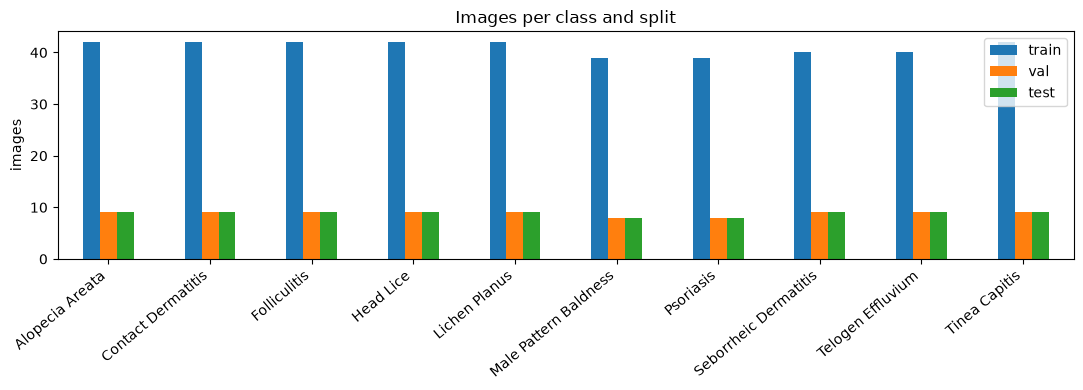

                       train    val   test
Alopecia Areata        0.102  0.102  0.102
Contact Dermatitis     0.102  0.102  0.102
Folliculitis           0.102  0.102  0.102
Head Lice              0.102  0.102  0.102
Lichen Planus          0.102  0.102  0.102
Male Pattern Baldness  0.095  0.091  0.091
Psoriasis              0.095  0.091  0.091
Seborrheic Dermatitis  0.098  0.102  0.102
Telogen Effluvium      0.098  0.102  0.102
Tinea Capitis          0.102  0.102  0.102


In [17]:
c2 = counts.drop(index="TOTAL")[SPLITS]
ax = c2.plot(kind="bar", figsize=(11, 4))
ax.set_ylabel("images"); ax.set_title("Images per class and split")
plt.xticks(rotation=40, ha="right"); plt.tight_layout()
plt.savefig(f"{RUN_DIR}/class_distribution.png", dpi=150); plt.show()
print((c2 / c2.sum()).round(3))

### Cell 8 - Load the three datasets
Expected output: `Found N files belonging to 10 classes` for each split.

In [18]:
def load_split(split, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        f"{DATA_DIR}/{split}", image_size=IMG_SIZE, batch_size=BATCH,
        label_mode="int", shuffle=shuffle, seed=SEED)

train_raw = load_split("train", True)
val_raw = load_split("val", False)
test_raw = load_split("test", False)

class_names = train_raw.class_names
NUM_CLASSES = len(class_names)
assert class_names == val_raw.class_names == test_raw.class_names
print("Classes:", class_names)

# file lists (val/test are not shuffled, so file order == prediction order)
train_files, val_files, test_files = train_raw.file_paths, val_raw.file_paths, test_raw.file_paths
print(len(train_files), len(val_files), len(test_files))

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_raw.prefetch(AUTOTUNE)
val_ds = val_raw.prefetch(AUTOTUNE)
test_ds = test_raw.prefetch(AUTOTUNE)
json.dump(class_names, open(f"{RUN_DIR}/class_names.json", "w"))

Found 410 files belonging to 10 classes.


python(5937) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Found 88 files belonging to 10 classes.
Found 88 files belonging to 10 classes.
Classes: ['Alopecia Areata', 'Contact Dermatitis', 'Folliculitis', 'Head Lice', 'Lichen Planus', 'Male Pattern Baldness', 'Psoriasis', 'Seborrheic Dermatitis', 'Telogen Effluvium', 'Tinea Capitis']
410 88 88


### Cell 9 - Leakage check (1/3): install and compute perceptual hashes
(Two code cells below: first the install, then the hashing. Run both.)
This is an **independent re-check after the re-split**. Hashes are computed on the final 224x224 images.

In [19]:
%pip install -q imagehash

python(5949) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Note: you may need to restart the kernel to use updated packages.


In [20]:
import imagehash
from PIL import ImageOps

def phash_int(im):
    bits = imagehash.phash(im).hash.flatten()
    return np.uint64(int("".join("1" if b else "0" for b in bits), 2))

def hashes(files, flip=False):
    out = np.zeros(len(files), dtype=np.uint64)
    for i, f in enumerate(files):
        with Image.open(f) as im:
            im = im.convert("RGB")
            out[i] = phash_int(ImageOps.mirror(im) if flip else im)
    return out

t0 = time.time()
H = {"train": hashes(train_files), "val": hashes(val_files), "test": hashes(test_files)}
H_flip = {"val": hashes(val_files, flip=True), "test": hashes(test_files, flip=True)}
print(f"Hashing done in {time.time() - t0:.0f}s")

Hashing done in 0s


### Cell 10 - Leakage check (2/3): compare splits
Counts image pairs from different splits whose pHash distance is small (<=2 = nearly identical, <=4 = very similar).
The `flipped` rows compare mirrored val/test images with train, to catch horizontally flipped copies.

**Interpretation:** ideally 0 or very few. Because the hash is now computed on padded images, numbers differ
from the earlier audit. A handful of pairs at distance 3-4 can be visually similar but different patients/photos;
look at a few before deciding anything.

In [21]:
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

def cross_pairs(a, b, thr):
    pairs = []
    for s in range(0, len(a), 256):
        x = a[s:s + 256, None] ^ b[None, :]
        d = POP[x.view(np.uint8).reshape(x.shape + (8,))].sum(axis=-1)
        for i, j in np.argwhere(d <= thr):
            pairs.append((s + int(i), int(j), int(d[i, j])))
    return pairs

rows, found = [], {}
for name, a, b in [("train vs val", H["train"], H["val"]),
                   ("train vs test", H["train"], H["test"]),
                   ("val vs test", H["val"], H["test"]),
                   ("train vs val (flipped)", H["train"], H_flip["val"]),
                   ("train vs test (flipped)", H["train"], H_flip["test"])]:
    p = cross_pairs(a, b, 4)
    found[name] = p
    rows.append({"comparison": name,
                 "pairs dist<=2": sum(1 for _, _, d in p if d <= 2),
                 "pairs dist<=4": len(p)})
leak_df = pd.DataFrame(rows)
print(leak_df.to_string(index=False))
leak_df.to_csv(f"{RUN_DIR}/leakage_check.csv", index=False)

             comparison  pairs dist<=2  pairs dist<=4
           train vs val              0              0
          train vs test              0              0
            val vs test              0              0
 train vs val (flipped)              0              0
train vs test (flipped)              0              0


### Cell 11 - Leakage check (3/3): look at the closest pairs between train and test
If pairs exist, this shows the 6 closest ones. Same lesion/photo in both => leakage.

In [22]:
p = sorted(found["train vs test"], key=lambda t: t[2])[:6]
if not p:
    print("No train/test pair with pHash distance <= 4.")
else:
    fig, ax = plt.subplots(len(p), 2, figsize=(5, 2.6 * len(p)))
    ax = np.atleast_2d(ax)
    for r, (i, j, d) in enumerate(p):
        for c, f in enumerate([train_files[i], test_files[j]]):
            ax[r, c].imshow(Image.open(f)); ax[r, c].axis("off")
            ax[r, c].set_title(("train" if c == 0 else "test") + f" | d={d}\n" + os.path.basename(f), fontsize=7)
    plt.tight_layout(); plt.savefig(f"{RUN_DIR}/closest_train_test_pairs.png", dpi=130); plt.show()

No train/test pair with pHash distance <= 4.


### Cell 12 - Look at some training images
Check that images look correct and that labels match the pictures.

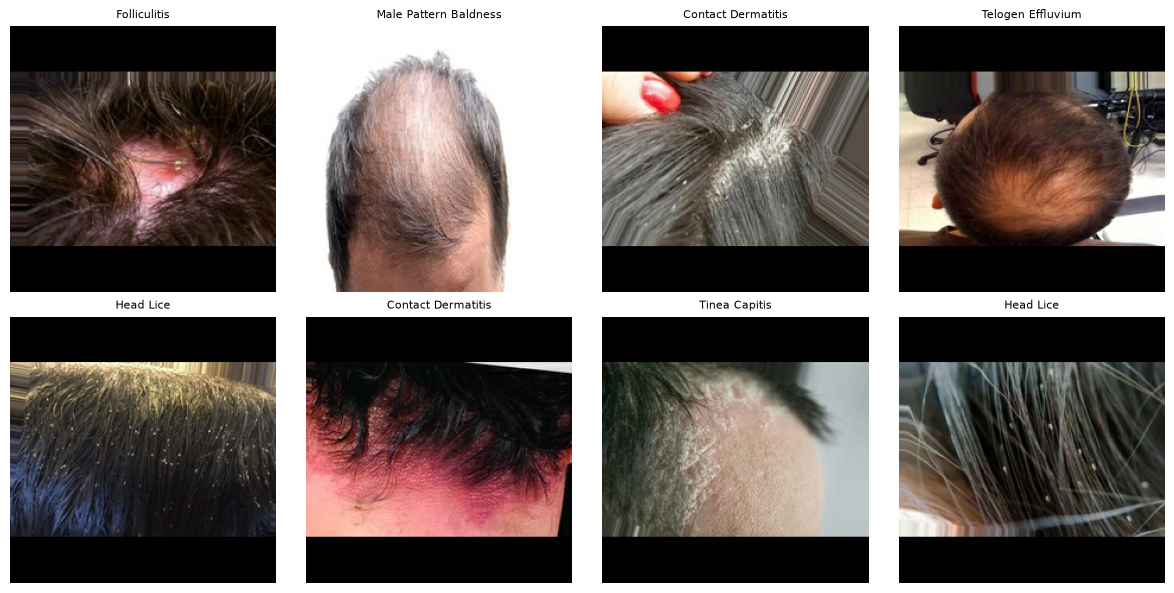

In [23]:
plt.figure(figsize=(12, 6))
for images, labels in train_raw.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]], fontsize=8); plt.axis("off")
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/sample_train_images.png", dpi=130); plt.show()

## C. Model definition and sanity checks

### Cell 13 - Augmentation layers (training only) and a visual check
Augmentation is part of the model, and Keras switches it **off** automatically for validation and test.
Same family as the repo (rotation, shift, zoom, flip). Left: original. Others: random augmentations of the same image.

2026-10-27 09:59:46.498199: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.
2026-10-27 09:59:54.061463: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.
2026-10-27 09:59:54.131166: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.
2026-10-27 09:59:54.171720: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.
2026-10-27 09:59:54.206652: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.


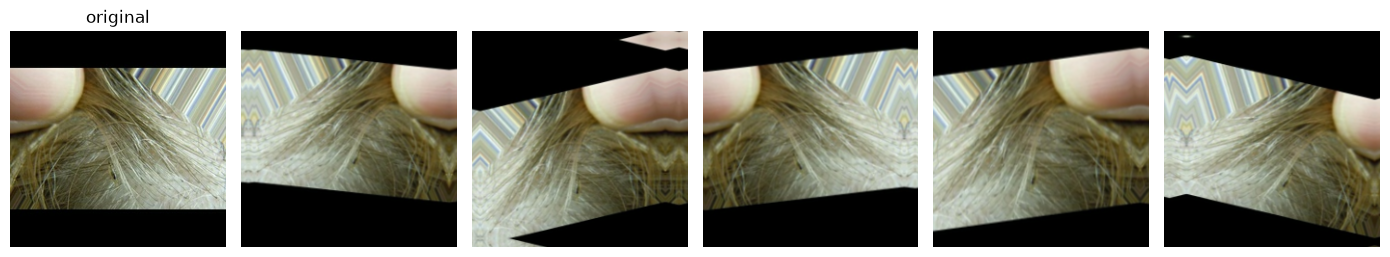

In [24]:
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(AUG["flip"]),
    tf.keras.layers.RandomRotation(AUG["rotation"]),
    tf.keras.layers.RandomTranslation(AUG["shift"], AUG["shift"]),
    tf.keras.layers.RandomZoom(AUG["zoom"]),
], name="augmentation")

img = next(iter(train_raw.take(1)))[0][:1]
plt.figure(figsize=(14, 3))
plt.subplot(1, 6, 1); plt.imshow(img[0].numpy().astype("uint8")); plt.title("original"); plt.axis("off")
for k in range(5):
    plt.subplot(1, 6, k + 2)
    plt.imshow(np.clip(augment(img, training=True)[0].numpy(), 0, 255).astype("uint8")); plt.axis("off")
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/augmentation_check.png", dpi=130); plt.show()

### Cell 14 - Model builder
VGG16 (ImageNet weights) + GlobalAveragePooling + Dense(512, ReLU) + Dropout + softmax layer (as in the repo).
Images are stored at 224x224, which is the native size of VGG16, so there is no resizing step.
`PREPROCESS = "imagenet_vgg"` applies `tf.keras.applications.vgg16.preprocess_input`; the older [0,1] option remains available as `repo_01`.
The last layer uses `dtype="float32"` so the softmax is numerically safe under mixed precision.

In [25]:
def build_model():
    base = tf.keras.applications.VGG16(input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
    base.trainable = False
    inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
    x = augment(inputs)
    if PREPROCESS == "imagenet_vgg":
        x = tf.keras.applications.vgg16.preprocess_input(x)
    else:
        x = tf.keras.layers.Rescaling(1 / 255.0)(x)
    if PREPROCESS == "imagenet_torch":
        x = tf.keras.layers.Normalization(mean=[0.485, 0.456, 0.406],
                                          variance=[0.229 ** 2, 0.224 ** 2, 0.225 ** 2])(x)
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(DENSE_UNITS, activation="relu")(x)
    x = tf.keras.layers.Dropout(DROPOUT)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32")(x)
    return tf.keras.Model(inputs, outputs), base

def make_optimizer(lr):
    if USE_LEGACY_ADAM and hasattr(tf.keras.optimizers, "legacy"):
        return tf.keras.optimizers.legacy.Adam(lr)
    return tf.keras.optimizers.Adam(lr)

def compile_model(m, lr):
    m.compile(optimizer=make_optimizer(lr),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print("builder ready")

builder ready


### Cell 15 - Sanity check 1: initial loss
A randomly initialised 10-class head should give loss close to ln(10) = 2.30 and accuracy near 10%.
Much higher or lower values mean something is wrong (labels, preprocessing, loss function).

In [26]:
xv, yv = next(iter(val_raw.take(1)))
m0, _ = build_model(); compile_model(m0, LR_P1)
loss0, acc0 = m0.evaluate(xv, yv, verbose=0)
print(f"initial loss = {loss0:.3f}   (expected about {np.log(NUM_CLASSES):.3f})")
print(f"initial acc  = {acc0:.3f}   (expected about {1 / NUM_CLASSES:.3f})")
del m0

initial loss = 0.000   (expected about 2.303)
initial acc  = 1.000   (expected about 0.100)


### Cell 16 - Sanity check 2: can the model overfit one small batch?
Train a throw-away model on a single batch of 32 images. Training accuracy should rise far above chance
(typically > 0.9). If it cannot, the pipeline has a bug. This model is discarded.

In [27]:
xb, yb = next(iter(train_raw.take(1)))
m1, _ = build_model(); compile_model(m1, LR_P1)
h = m1.fit(xb, yb, epochs=40, verbose=0)
print(f"loss  {h.history['loss'][0]:.3f} -> {h.history['loss'][-1]:.3f}")
print(f"acc   {h.history['accuracy'][0]:.3f} -> {h.history['accuracy'][-1]:.3f}")
del m1
tf.keras.backend.clear_session()

2026-10-27 10:00:18.450022: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.
2026-10-27 10:00:26.430443: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.
2026-10-27 10:00:26.582858: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.
2026-10-27 10:00:26.718810: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.
2026-10-27 10:00:26.825720: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.
2026-10-27 10:00:26.938859: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation

loss  2.455 -> 0.772
acc   0.000 -> 0.750


## D. Training

### Cell 17 - Build the real model
Expected: about 14.98M total parameters, of which about 267,786 are trainable (the new head:
512 x 512 + 512 + 512 x 10 + 10).

In [28]:
tf.keras.utils.set_random_seed(SEED)
model, base = build_model()
compile_model(model, LR_P1)
model.summary(show_trainable=True)
n_train = int(sum(np.prod(w.shape) for w in model.trainable_weights))
n_total = int(model.count_params())
print(f"Trainable params: {n_train:,} / {n_total:,}")

Model: "model"
____________________________________________________________________________
 Layer (type)                Output Shape              Param #   Trainable  
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         Y          
                                                                            
 augmentation (Sequential)   (None, 224, 224, 3)       0         Y          
                                                                            
 rescaling (Rescaling)       (None, 224, 224, 3)       0         Y          
                                                                            
 vgg16 (Functional)          (None, 7, 7, 512)         1471468   N          
                                                       8                    
                                                                            
 global_average_pooling2d (  (None, 512)               0         Y          
 GlobalAveragePooling2D)                                     

### Cell 18 - Callbacks
Early stopping and checkpoints monitor **validation loss** (never the test set).

In [29]:
CKPT_P1 = f"{RUN_DIR}/ckpt_phase1.keras"
CKPT_P2 = f"{RUN_DIR}/ckpt_phase2.keras"

def make_callbacks(ckpt, patience, log_name):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True, verbose=0),
        tf.keras.callbacks.CSVLogger(f"{RUN_DIR}/{log_name}.csv"),
    ]
print("ok")

ok


### Cell 19 - Phase 1: train the classification head (backbone frozen)
Watch `val_loss`: it should decrease in the first epochs.

In [30]:
t0 = time.time()
h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_P1,
               callbacks=make_callbacks(CKPT_P1, ES_PATIENCE_P1, "log_phase1"))
print(f"Phase 1 finished in {(time.time() - t0) / 60:.1f} min")

Epoch 1/5


2026-10-27 10:00:33.621645: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.


 2/52 [>.............................] - ETA: 7s - loss: 2.6297 - accuracy: 0.1875  

2026-10-27 10:00:35.102146: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.
2026-10-27 10:00:35.249633: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.


 4/52 [=>............................] - ETA: 6s - loss: 2.7968 - accuracy: 0.0938

...

50/52 [===========================>..] - ETA: 0s - loss: 1.7573 - accuracy: 0.3925

2026-10-27 10:01:44.256195: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.
2026-10-27 10:01:44.398127: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.


51/52 [============================>.] - ETA: 0s - loss: 1.7606 - accuracy: 0.3946

2026-10-27 10:01:44.515992: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.


52/52 [==============================] - 9s 181ms/step - loss: 1.7620 - accuracy: 0.3951 - val_loss: 1.8583 - val_accuracy: 0.3636 - lr: 0.0010
Phase 1 finished in 1.3 min


### Cell 20 - Phase 1 result

In [31]:
d1 = pd.DataFrame(h1.history)
best1 = d1["val_loss"].idxmin()
print(f"Best epoch (phase 1): {best1 + 1}  val_loss={d1.loc[best1, 'val_loss']:.4f}  val_acc={d1.loc[best1, 'val_accuracy']:.4f}")
print(d1.round(4).to_string())

Best epoch (phase 1): 5  val_loss=1.8583  val_acc=0.3636
     loss  accuracy  val_loss  val_accuracy     lr
0  2.4424    0.1732    2.1494        0.2841  0.001
1  2.0483    0.2829    2.0507        0.3409  0.001
2  1.9099    0.3220    1.9633        0.3523  0.001
3  1.8100    0.3805    1.9671        0.3409  0.001
4  1.7620    0.3951    1.8583        0.3636  0.001


### Cell 21 - Phase 2 setup: unfreeze the last conv block (block5) of VGG16
All layers from `FINE_TUNE_FROM_LAYER` (`block5_conv1`) onward are trained (3 conv layers); everything before stays frozen.
VGG16 has no BatchNorm layers, so nothing else needs freezing.
Learning rate drops to `LR_P2`. The model is recompiled (required after changing `trainable`).

In [32]:
FINE_TUNE_AT = next(i for i, l in enumerate(base.layers) if l.name == FINE_TUNE_FROM_LAYER)
print(f"Unfreezing from layer index {FINE_TUNE_AT} ({FINE_TUNE_FROM_LAYER}) of {len(base.layers)} backbone layers")

base.trainable = True
for layer in base.layers[:FINE_TUNE_AT]:
    layer.trainable = False

compile_model(model, LR_P2)
n_train2 = int(sum(np.prod(w.shape) for w in model.trainable_weights))
print(f"Trainable params now: {n_train2:,} / {n_total:,}")

Unfreezing from layer index 15 (block5_conv1) of 19 backbone layers
Trainable params now: 7,347,210 / 14,982,474


### Cell 22 - Phase 2: fine-tuning
This phase starts from the best phase-1 weights (restored by early stopping).

In [33]:
t0 = time.time()
h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_P2,
               callbacks=make_callbacks(CKPT_P2, ES_PATIENCE_P2, "log_phase2"))
print(f"Phase 2 finished in {(time.time() - t0) / 60:.1f} min")

Epoch 1/3


2026-10-27 10:01:51.774864: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.


 1/52 [..............................] - ETA: 3:35 - loss: 1.3632 - accuracy: 0.5000

2026-10-27 10:01:53.249429: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.


 2/52 [>.............................] - ETA: 28s - loss: 1.3155 - accuracy: 0.5625 

...

50/52 [===========================>..] - ETA: 0s - loss: 1.2979 - accuracy: 0.5700

2026-10-27 10:02:19.219411: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.
2026-10-27 10:02:19.334910: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.


52/52 [==============================] - ETA: 0s - loss: 1.2960 - accuracy: 0.5732

2026-10-27 10:02:19.453870: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.


52/52 [==============================] - 9s 170ms/step - loss: 1.2960 - accuracy: 0.5732 - val_loss: 1.6172 - val_accuracy: 0.4659 - lr: 1.0000e-05
Phase 2 finished in 0.5 min


### Cell 23 - Training curves (both phases)
Look for overfitting: train accuracy far above val accuracy and val loss rising.

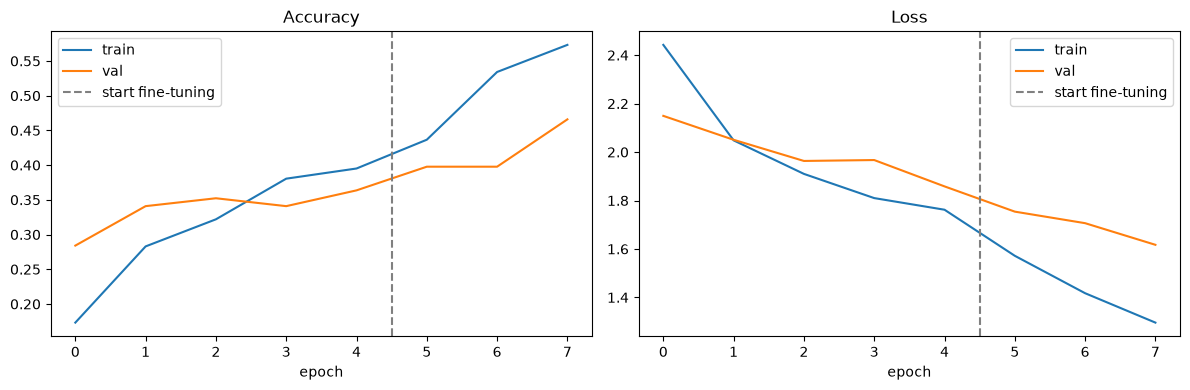

In [34]:
d2 = pd.DataFrame(h2.history)
hist = pd.concat([d1.assign(phase=1), d2.assign(phase=2)], ignore_index=True)
hist.to_csv(f"{RUN_DIR}/history_all.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, k, t in zip(ax, ["accuracy", "loss"], ["Accuracy", "Loss"]):
    a.plot(hist[k], label="train"); a.plot(hist["val_" + k], label="val")
    a.axvline(len(d1) - 0.5, color="gray", linestyle="--", label="start fine-tuning")
    a.set_title(t); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/training_curves.png", dpi=150); plt.show()

### Cell 24 - Choose the final model using VALIDATION loss only
Fine-tuning does not always help. We evaluate both checkpoints on the validation set and keep the better one.

In [35]:
res = {}
for name, path in [("phase1", CKPT_P1), ("phase2", CKPT_P2)]:
    if os.path.exists(path):
        m = tf.keras.models.load_model(path)
        l, a = m.evaluate(val_ds, verbose=0)
        res[name] = {"val_loss": float(l), "val_acc": float(a), "path": path}
        print(f"{name}: val_loss={l:.4f}  val_acc={a:.4f}")
if not res:
    raise FileNotFoundError("No completed checkpoint found. Run Phase 1 and Phase 2 before evaluation.")
best_name = min(res, key=lambda k: res[k]["val_loss"])
print("Selected:", best_name)
final_model = tf.keras.models.load_model(res[best_name]["path"])
json.dump({"selected": best_name, **res}, open(f"{RUN_DIR}/model_selection.json", "w"), indent=2)

phase1: val_loss=1.8583  val_acc=0.3636
phase2: val_loss=1.6172  val_acc=0.4659
Selected: phase2


## E. Final evaluation on the TEST set
**Run Cells 25-32 once.** Do not change any hyper-parameter after seeing test results,
otherwise the test set stops being independent. If you must change something, repeat the experiment
under a new RUN_NAME and say so in the report.

### Cell 25 - Predictions on the test set

In [36]:
test_batches = []
test_labels = []
for images, labels in test_ds:
    pred = final_model(images, training=False)
    if isinstance(pred, tf.RaggedTensor):
        pred = pred.to_tensor()
    test_batches.append(np.asarray(pred, dtype="float64"))
    test_labels.append(labels.numpy())
if not test_batches:
    raise ValueError("The test dataset is empty; cannot calculate metrics.")
y_true = np.concatenate(test_labels)
y_prob = np.concatenate(test_batches, axis=0)
y_prob = y_prob / y_prob.sum(axis=1, keepdims=True)   # exact row sums for roc_auc
y_pred = y_prob.argmax(axis=1)
assert len(y_true) == len(y_pred) == len(test_files)

pred_df = pd.DataFrame({
    "file": [os.path.relpath(f, DATA_DIR) for f in test_files],
    "true": [class_names[i] for i in y_true],
    "pred": [class_names[i] for i in y_pred],
    "confidence": y_prob.max(axis=1),
    **{f"p_{c}": y_prob[:, i] for i, c in enumerate(class_names)},
})
pred_df.to_csv(f"{RUN_DIR}/test_predictions.csv", index=False)
print(pred_df.head())

                                            file             true  \
0  test/Alopecia Areata/alopecia_areata_0045.jpg  Alopecia Areata   
1  test/Alopecia Areata/alopecia_areata_0343.jpg  Alopecia Areata   
2  test/Alopecia Areata/alopecia_areata_0349.jpg  Alopecia Areata   
3  test/Alopecia Areata/alopecia_areata_0385.jpg  Alopecia Areata   
4  test/Alopecia Areata/alopecia_areata_0387.jpg  Alopecia Areata   

              pred  confidence  p_Alopecia Areata  p_Contact Dermatitis  \
0  Alopecia Areata    0.815694           0.815694              0.002750   
1  Alopecia Areata    0.580302           0.580302              0.027491   
2  Alopecia Areata    0.672167           0.672167              0.016739   
3    Tinea Capitis    0.274159           0.205912              0.006120   
4  Alopecia Areata    0.830330           0.830330              0.009013   

   p_Folliculitis  p_Head Lice  p_Lichen Planus  p_Male Pattern Baldness  \
0        0.009822     0.008547         0.019399           

### Cell 26 - Overall metrics

In [37]:
acc = accuracy_score(y_true, y_pred)
bal = balanced_accuracy_score(y_true, y_pred)
p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
f1w = f1_score(y_true, y_pred, average="weighted", zero_division=0)
kappa = cohen_kappa_score(y_true, y_pred)
try:
    auc = roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro", labels=list(range(NUM_CLASSES)))
except ValueError:
    auc = float("nan")

metrics = {"accuracy": acc, "balanced_accuracy": bal, "macro_precision": p, "macro_recall": r,
           "macro_f1": f1, "weighted_f1": f1w, "cohen_kappa": kappa, "macro_auc_ovr": auc}
metrics = {k: float(v) for k, v in metrics.items()}
for k, v in metrics.items():
    print(f"{k:18s}: {v:.4f}")
json.dump(metrics, open(f"{RUN_DIR}/test_metrics.json", "w"), indent=2)

accuracy          : 0.4659
balanced_accuracy : 0.4611
macro_precision   : 0.5743
macro_recall      : 0.4611
macro_f1          : 0.4323
weighted_f1       : 0.4356
cohen_kappa       : 0.4059
macro_auc_ovr     : 0.8471


### Cell 27 - Per-class precision / recall / F1
Look for weak classes, then confirm in the confusion matrix.

In [38]:
report = classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0)
print(report)
open(f"{RUN_DIR}/classification_report.txt", "w").write(report)
pd.DataFrame(classification_report(y_true, y_pred, target_names=class_names, output_dict=True,
                                   zero_division=0)).T.to_csv(f"{RUN_DIR}/classification_report.csv")

                       precision    recall  f1-score   support

      Alopecia Areata     0.5333    0.8889    0.6667         9
   Contact Dermatitis     0.8000    0.4444    0.5714         9
         Folliculitis     1.0000    0.1111    0.2000         9
            Head Lice     0.6923    1.0000    0.8182         9
        Lichen Planus     0.3333    0.3333    0.3333         9
Male Pattern Baldness     0.3750    0.3750    0.3750         8
            Psoriasis     0.5000    0.1250    0.2000         8
Seborrheic Dermatitis     0.2593    0.7778    0.3889         9
    Telogen Effluvium     0.7500    0.3333    0.4615         9
        Tinea Capitis     0.5000    0.2222    0.3077         9

             accuracy                         0.4659        88
            macro avg     0.5743    0.4611    0.4323        88
         weighted avg     0.5774    0.4659    0.4356        88



### Cell 28 - Confusion matrices (counts and row-normalised)

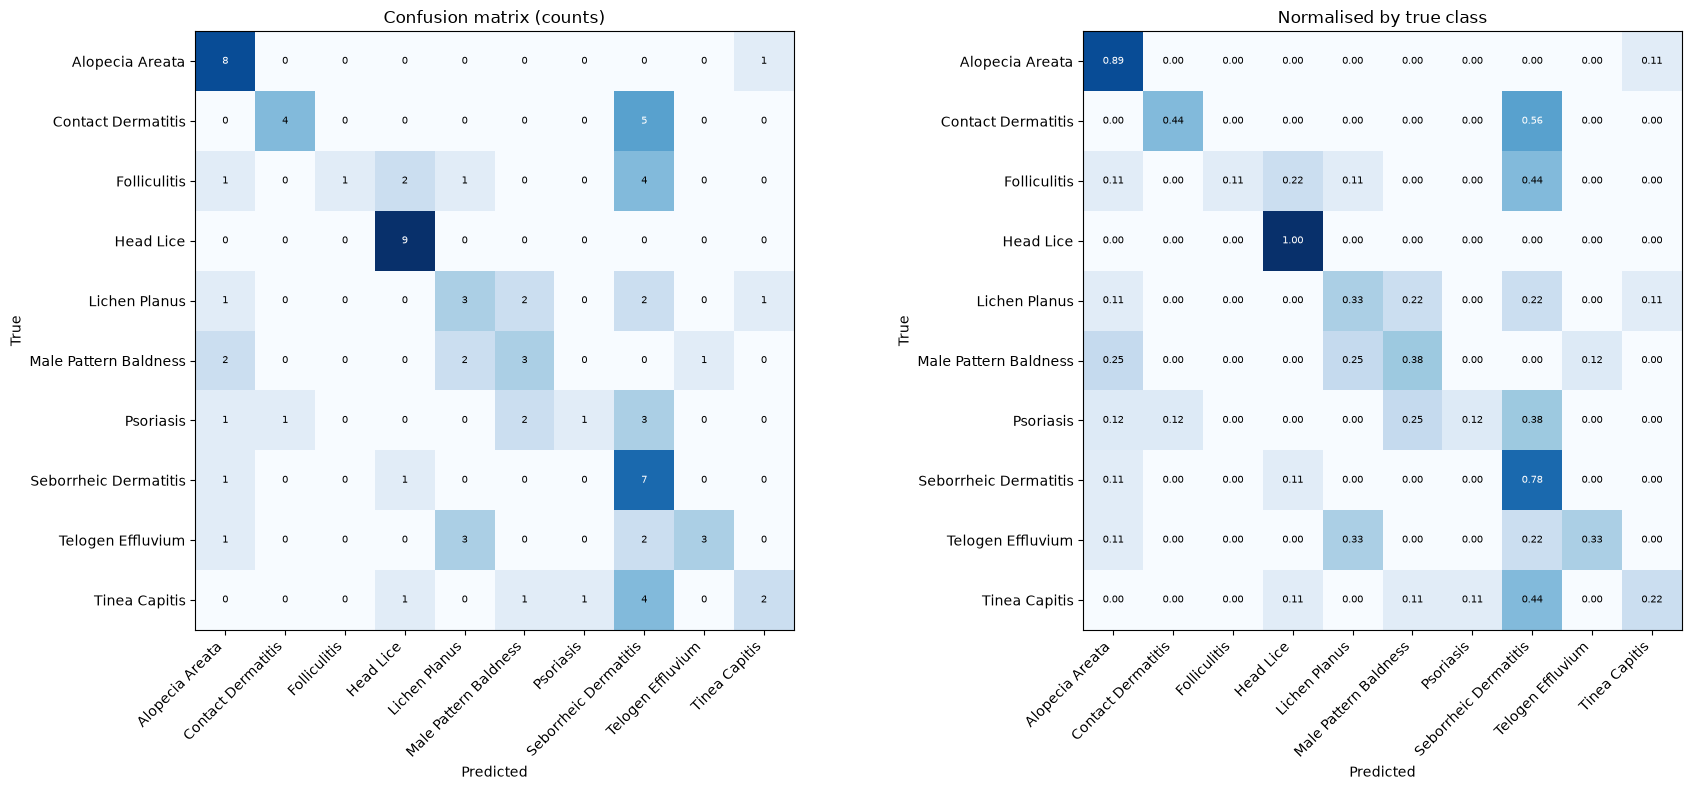

In [39]:
cm = confusion_matrix(y_true, y_pred)
cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(1, 2, figsize=(18, 8))
for a, M, title, fmt in [(ax[0], cm, "Confusion matrix (counts)", "d"), (ax[1], cmn, "Normalised by true class", ".2f")]:
    im = a.imshow(M, cmap="Blues")
    a.set_xticks(range(NUM_CLASSES)); a.set_yticks(range(NUM_CLASSES))
    a.set_xticklabels(class_names, rotation=45, ha="right"); a.set_yticklabels(class_names)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            a.text(j, i, format(M[i, j], fmt), ha="center", va="center", fontsize=7,
                   color="white" if M[i, j] > M.max() / 2 else "black")
    a.set_xlabel("Predicted"); a.set_ylabel("True"); a.set_title(title)
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/confusion_matrix.png", dpi=150); plt.show()
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(f"{RUN_DIR}/confusion_matrix.csv")

### Cell 29 - 95% bootstrap confidence intervals
Resamples the test set 1000 times. Report as `accuracy = 0.xx (95% CI lo-hi)`.

In [40]:
rng = np.random.default_rng(SEED)
n = len(y_true)
accs, f1s = [], []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    accs.append((y_true[idx] == y_pred[idx]).mean())
    f1s.append(f1_score(y_true[idx], y_pred[idx], average="macro", zero_division=0))
ci = {"accuracy_ci95": [float(np.percentile(accs, 2.5)), float(np.percentile(accs, 97.5))],
      "macro_f1_ci95": [float(np.percentile(f1s, 2.5)), float(np.percentile(f1s, 97.5))]}
print(f"Accuracy : {acc:.4f}  95% CI [{ci['accuracy_ci95'][0]:.4f}, {ci['accuracy_ci95'][1]:.4f}]")
print(f"Macro-F1 : {f1:.4f}  95% CI [{ci['macro_f1_ci95'][0]:.4f}, {ci['macro_f1_ci95'][1]:.4f}]")
json.dump(ci, open(f"{RUN_DIR}/test_bootstrap_ci.json", "w"), indent=2)

Accuracy : 0.4659  95% CI [0.3634, 0.5685]
Macro-F1 : 0.4323  95% CI [0.3146, 0.5142]


### Cell 30 - Most confused class pairs

In [41]:
off = [(class_names[i], class_names[j], int(cm[i, j])) for i in range(NUM_CLASSES)
       for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
conf_df = pd.DataFrame(sorted(off, key=lambda t: -t[2]), columns=["true", "predicted_as", "count"])
print(conf_df.head(10).to_string(index=False))
conf_df.to_csv(f"{RUN_DIR}/confused_pairs.csv", index=False)

                 true          predicted_as  count
   Contact Dermatitis Seborrheic Dermatitis      5
         Folliculitis Seborrheic Dermatitis      4
        Tinea Capitis Seborrheic Dermatitis      4
            Psoriasis Seborrheic Dermatitis      3
    Telogen Effluvium         Lichen Planus      3
         Folliculitis             Head Lice      2
        Lichen Planus Male Pattern Baldness      2
        Lichen Planus Seborrheic Dermatitis      2
Male Pattern Baldness       Alopecia Areata      2
Male Pattern Baldness         Lichen Planus      2


### Cell 31 - Confident mistakes (error analysis)
The 12 test images the model got wrong with the highest confidence. Check them by eye:
label noise, hard images, or a real model weakness? This is a good discussion point for the thesis.

47 wrong predictions out of 88


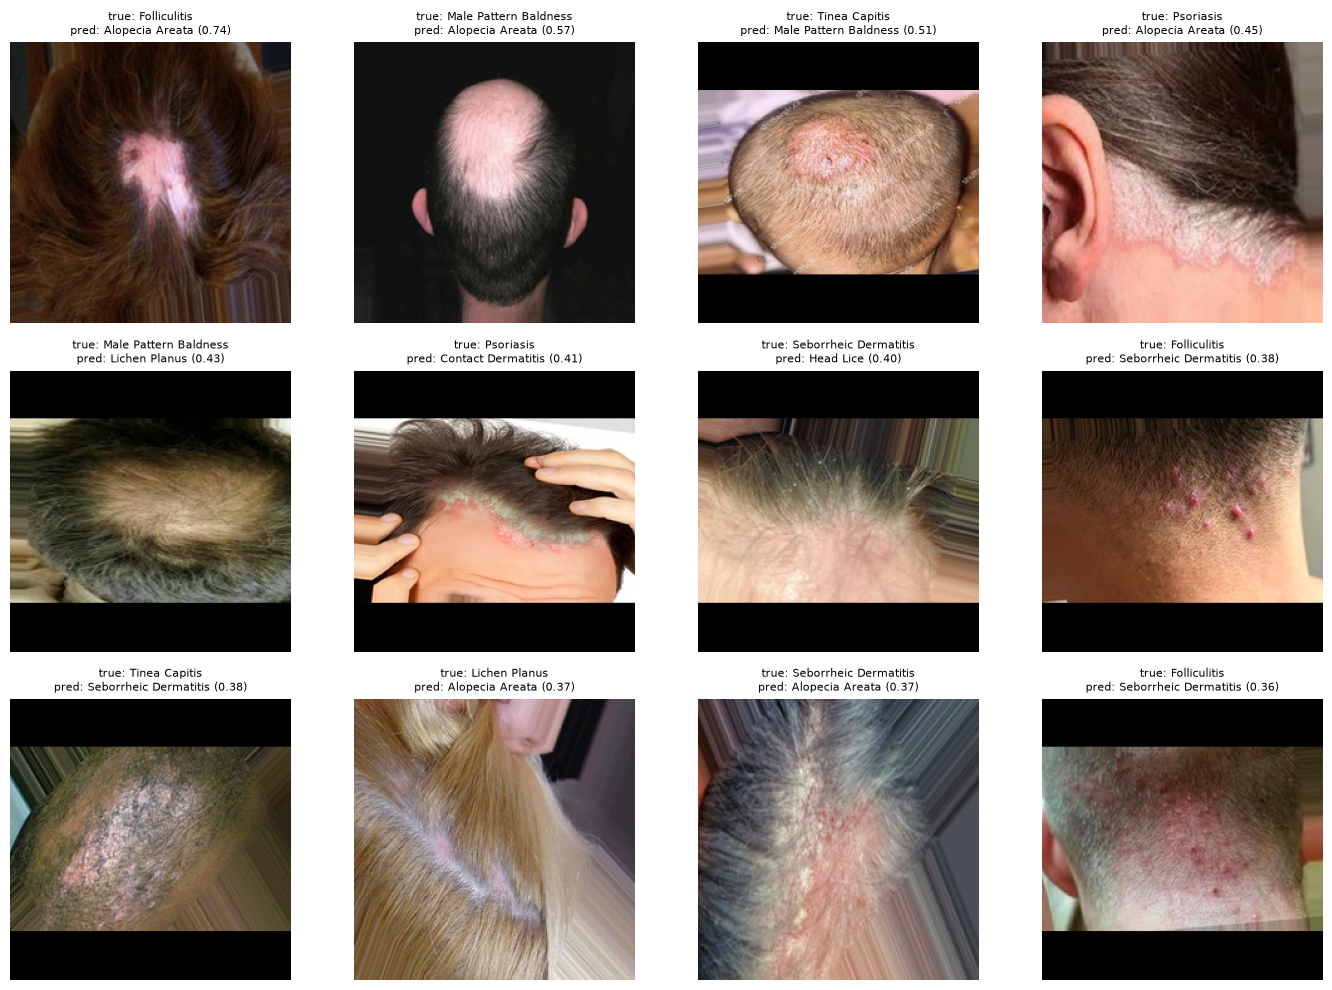

In [42]:
wrong = np.where(y_true != y_pred)[0]
print(f"{len(wrong)} wrong predictions out of {len(y_true)}")
if len(wrong):
    top = wrong[np.argsort(-y_prob.max(axis=1)[wrong])][:12]
    fig, ax = plt.subplots(3, 4, figsize=(14, 10))
    for a, i in zip(ax.ravel(), top):
        a.imshow(Image.open(test_files[i])); a.axis("off")
        a.set_title(f"true: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]} ({y_prob[i].max():.2f})", fontsize=8)
    for a in ax.ravel()[len(top):]:
        a.axis("off")
    plt.tight_layout(); plt.savefig(f"{RUN_DIR}/confident_errors.png", dpi=130); plt.show()

### Cell 32 - Confidence vs correctness
A well-behaved model is more confident when it is right.

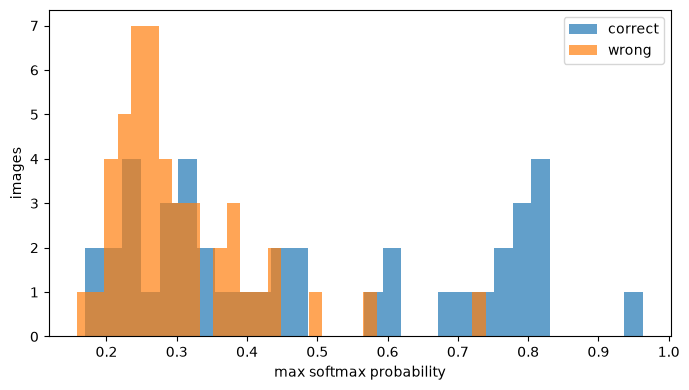

mean confidence  correct: 0.485   wrong: 0.304


In [43]:
conf = y_prob.max(axis=1)
plt.figure(figsize=(7, 4))
plt.hist(conf[y_true == y_pred], bins=30, alpha=0.7, label="correct")
plt.hist(conf[y_true != y_pred], bins=30, alpha=0.7, label="wrong")
plt.xlabel("max softmax probability"); plt.ylabel("images"); plt.legend()
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/confidence_hist.png", dpi=130); plt.show()
print(f"mean confidence  correct: {conf[y_true == y_pred].mean():.3f}   wrong: {conf[y_true != y_pred].mean() if (y_true != y_pred).any() else float('nan'):.3f}")

## F. Save everything

### Cell 33 - Save the final model and an experiment summary

In [44]:
final_model.save(f"{RUN_DIR}/final_model.keras")
summary = {
    "run_name": RUN_NAME,
    "seed": SEED,
    "mixed_precision": MIXED_PRECISION,
    "preprocess": PREPROCESS,
    "fine_tune_from_layer": FINE_TUNE_FROM_LAYER,
    "selected_checkpoint": best_name,
    "n_images": {"train": len(train_files), "val": len(val_files), "test": len(test_files)},
    "val": {k: res[best_name][k] for k in ["val_loss", "val_acc"]},
    "test_metrics": metrics,
    "test_bootstrap_ci": ci,
    "tf_version": tf.__version__,
}
json.dump(summary, open(f"{RUN_DIR}/experiment_summary.json", "w"), indent=2)
print(json.dumps(summary, indent=2))
print("\nAll files saved in:", RUN_DIR)
print(sorted(os.listdir(RUN_DIR)))

{
  "run_name": "vgg16_seed42_sub5pct_20261027_095932",
  "seed": 42,
  "mixed_precision": false,
  "preprocess": "repo_01",
  "fine_tune_from_layer": "block5_conv1",
  "selected_checkpoint": "phase2",
  "n_images": {
    "train": 410,
    "val": 88,
    "test": 88
  },
  "val": {
    "val_loss": 1.6171694993972778,
    "val_acc": 0.46590909361839294
  },
  "test_metrics": {
    "accuracy": 0.4659090909090909,
    "balanced_accuracy": 0.4611111111111111,
    "macro_precision": 0.5743233618233619,
    "macro_recall": 0.4611111111111111,
    "macro_f1": 0.43227300477300473,
    "weighted_f1": 0.4355633003360275,
    "cohen_kappa": 0.4059178397012351,
    "macro_auc_ovr": 0.8471231100562587
  },
  "test_bootstrap_ci": {
    "accuracy_ci95": [
      0.3633522727272728,
      0.5684659090909089
    ],
    "macro_f1_ci95": [
      0.3146476656095842,
      0.5141527640682052
    ]
  },
  "tf_version": "2.15.1"
}

All files saved in: /Users/nngoc/Documents/Hair Diseases/Hair-Disease-Research/

## G. 5-fold cross-validation (VGG16, train + val only; the test set stays untouched)

**This section is self-contained.** It only needs Cells 1-5 (imports, config, seed, unzip) to have been run in the current
session, so after restarting the kernel you can run Cells 1-5 and then jump straight here (sections B-F are not required).

Design (same as the Colab `CV5_HD` notebook, so results are comparable):
- Folds = `StratifiedGroupKFold(5)` on **train + val**. Near-duplicate and mirrored images (pHash distance <= 4) are put in
  the same group, so a near-duplicate can never be in the training part and the held-out part of the same fold.
- Inside each fold, 1/10 of the training part is an inner validation set (early stopping + checkpoint choice).
  The held-out fold is evaluated **once**. The original test set is only predicted, never used for any choice.
- Same VGG16 pipeline as above: Phase 1 (head) -> Phase 2 (fine-tune `block5`), Dense(512) head, pixels / 255.

**Made for a Mac with 8 GB RAM:** batch 16, no in-memory image cache (images are read from the SSD every epoch),
checkpoints deleted after each fold, memory released between folds, and every finished fold is saved so you can stop and resume.
Tip: close other apps (browser!) before training. If the kernel dies, set `CV_BATCH = 8`.

### Cell 34 - Cross-validation settings
**First run with `CV_SMOKE_TEST = True`** (about 300 images, 1 + 1 epochs per fold): it checks the whole pipeline in a few
minutes. Then set it back to `False` for the real run. Smoke-test results are meaningless and are saved in separate folders.
`CV_EPOCHS_P1 + CV_EPOCHS_P2` = at most 20 epochs per fold (early stopping usually stops earlier).

In [19]:
import gc, glob
import imagehash
from PIL import ImageOps
from scipy import stats
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold

# ------------------------------------------------------------- EDIT HERE
CV_SMOKE_TEST = False          # True = quick pipeline check, False = real 5-fold run
CV_RESUME_RUN_NAME = None     # e.g. "vgg16_cv5_seed42_20261025_090000" to continue an interrupted run
CV_FOLDS_TO_RUN = [0, 1, 2, 3, 4]         # run all five folds in one session
CV_BATCH = 8                  # safer for Apple M2 with 8 GB RAM
# ---------------------------------------------------------------------
N_FOLDS = 5
CV_EPOCHS_P1, CV_ES_P1 = 3, 1
CV_EPOCHS_P2, CV_ES_P2 = 5, 2
GROUP_THR = 4                 # pHash distance <= 4 => same group (same threshold as the leakage check above)
INNER_SPLITS = 10             # inner validation = 1/10 of the training part of each fold
CV_SAVE_FOLD_MODELS = False   # True: keep each fold's final model (~60 MB each)

SUFFIX = TAG + ("_smoke" if CV_SMOKE_TEST else "")
if CV_SMOKE_TEST:
    CV_EPOCHS_P1, CV_ES_P1, CV_EPOCHS_P2, CV_ES_P2 = 1, 1, 1, 1
CV_FOLDS_DIR = f"{RESULTS_ROOT}/cv5_folds_seed{SEED}{SUFFIX}"    # shared by every model (also by the Colab CV notebook)
CV_RUN_NAME = CV_RESUME_RUN_NAME or (f"{MODEL_NAME}_cv5_seed{SEED}{SUFFIX}_" + datetime.datetime.now().strftime("%Y%m%d_%H%M%S"))
CV_RUN_DIR = f"{RESULTS_ROOT}/{CV_RUN_NAME}"
CV_CKPT_DIR = f"{CV_RUN_DIR}/_tmp_ckpt"
for d in (CV_FOLDS_DIR, CV_RUN_DIR, CV_CKPT_DIR):
    os.makedirs(d, exist_ok=True)
assert os.path.exists(DATA_DIR), "Dataset folder not found - run Cell 5 (unzip) first."

cv_cfg = {k: v for k, v in globals().items() if (k.startswith("CV_") or k in ("N_FOLDS", "GROUP_THR", "INNER_SPLITS", "SUFFIX"))
          and isinstance(v, (int, float, str, bool, list))}
cv_cfg.update({"DATA_MODE": DATA_MODE, "USE_SUBSET": USE_SUBSET, "SUBSET_FRACTION": SUBSET_FRACTION, "SEED": SEED, "MODEL_NAME": MODEL_NAME, "IMG_SIZE": IMG_SIZE, "DENSE_UNITS": DENSE_UNITS, "DROPOUT": DROPOUT,
               "LR_P1": LR_P1, "LR_P2": LR_P2, "FINE_TUNE_FROM_LAYER": FINE_TUNE_FROM_LAYER, "MIXED_PRECISION": MIXED_PRECISION})
if not os.path.exists(f"{CV_RUN_DIR}/cv_config.json"):
    json.dump(cv_cfg, open(f"{CV_RUN_DIR}/cv_config.json", "w"), indent=2, default=str)
print("CV run folder:", CV_RUN_DIR, "(resuming)" if CV_RESUME_RUN_NAME else "(new run)")
print("SMOKE TEST MODE - results are meaningless" if CV_SMOKE_TEST else "REAL RUN")
print(json.dumps(cv_cfg, indent=2, default=str))

CV run folder: /Users/nngoc/Documents/Hair Diseases/Hair-Disease-Research/results/vgg16_cv5_seed42_sub5pct_20261027_122209 (new run)
REAL RUN
{
  "CV_SMOKE_TEST": false,
  "CV_FOLDS_TO_RUN": [
    0,
    1,
    2,
    3,
    4
  ],
  "CV_BATCH": 8,
  "N_FOLDS": 5,
  "CV_EPOCHS_P1": 3,
  "CV_ES_P1": 1,
  "CV_EPOCHS_P2": 5,
  "CV_ES_P2": 2,
  "GROUP_THR": 4,
  "INNER_SPLITS": 10,
  "CV_SAVE_FOLD_MODELS": false,
  "SUFFIX": "_sub5pct",
  "CV_FOLDS_DIR": "/Users/nngoc/Documents/Hair Diseases/Hair-Disease-Research/results/cv5_folds_seed42_sub5pct",
  "CV_RUN_NAME": "vgg16_cv5_seed42_sub5pct_20261027_122209",
  "CV_RUN_DIR": "/Users/nngoc/Documents/Hair Diseases/Hair-Disease-Research/results/vgg16_cv5_seed42_sub5pct_20261027_122209",
  "CV_CKPT_DIR": "/Users/nngoc/Documents/Hair Diseases/Hair-Disease-Research/results/vgg16_cv5_seed42_sub5pct_20261027_122209/_tmp_ckpt",
  "CV_NUM_CLASSES": 10,
  "CV_FOLDS_CSV": "/Users/nngoc/Documents/Hair Diseases/Hair-Disease-Research/results/cv5_folds_seed

### Cell 35 - Build (or load) the group-aware folds
Lists train + val + test images, computes perceptual hashes (a few minutes, only the first time), groups near-duplicates and
creates the 5 folds. The folds are saved in `results/cv5_folds_seed42/folds.csv` and re-used on later runs.

**Check the output:** `groups spanning several folds` must be 0, the largest group should be small (< 2% of the data), and each
fold should contain all 10 classes in similar proportions.

In [20]:
IMG_EXT = (".jpg", ".jpeg", ".png")
cv_classes = sorted(d for d in os.listdir(f"{DATA_DIR}/train") if os.path.isdir(f"{DATA_DIR}/train/{d}") and not d.startswith("."))
CV_NUM_CLASSES = len(cv_classes)

def cv_list(splits):
    rows = []
    for s in splits:
        for ci, c in enumerate(cv_classes):
            for f in sorted(os.listdir(f"{DATA_DIR}/{s}/{c}")):
                if f.lower().endswith(IMG_EXT):
                    rows.append((f"{s}/{c}/{f}", c, ci, s))
    return pd.DataFrame(rows, columns=["file", "class", "label", "orig_split"])

cv_dev, cv_test = cv_list(["train", "val"]), cv_list(["test"])
if CV_SMOKE_TEST:   # tiny subset, only to check that the pipeline runs
    _per_class = lambda df, n: pd.concat([g.sample(min(len(g), n), random_state=SEED) for _, g in df.groupby("class")]).reset_index(drop=True)
    cv_dev = _per_class(cv_dev, 30)
    cv_test = _per_class(cv_test, 12)
print(f"development (train+val): {len(cv_dev)} | test: {len(cv_test)} | classes: {CV_NUM_CLASSES}")

CV_POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
def cv_phash(im):
    bits = imagehash.phash(im).hash.flatten()
    return np.uint64(int("".join("1" if b else "0" for b in bits), 2))
def cv_hashes(files, flip=False):
    out = np.zeros(len(files), dtype=np.uint64)
    for i, f in enumerate(files):
        with Image.open(f"{DATA_DIR}/{f}") as im:
            im = im.convert("RGB")
            out[i] = cv_phash(ImageOps.mirror(im) if flip else im)
    return out
def cv_close_pairs(a, b, thr):
    rows, cols = [], []
    for s in range(0, len(a), 256):
        x = a[s:s + 256, None] ^ b[None, :]
        d = CV_POP[x.view(np.uint8).reshape(x.shape + (8,))].sum(axis=-1)
        r, c = np.nonzero(d <= thr)
        rows.append(r + s); cols.append(c)
    return np.concatenate(rows), np.concatenate(cols)

CV_FOLDS_CSV = f"{CV_FOLDS_DIR}/folds.csv"
if os.path.exists(CV_FOLDS_CSV):
    saved = pd.read_csv(CV_FOLDS_CSV)
    assert set(saved.file) == set(cv_dev.file) and len(saved) == len(cv_dev), "folds.csv does not match the current data!"
    cv_dev = cv_dev.merge(saved[["file", "group", "fold"]], on="file", how="left")
    assert cv_dev.fold.notna().all()
    cv_dev["fold"] = cv_dev.fold.astype(int)
    print("Loaded existing folds:", CV_FOLDS_CSV)
else:
    t0 = time.time()
    H1, H2 = cv_hashes(cv_dev.file.tolist()), cv_hashes(cv_dev.file.tolist(), flip=True)
    print(f"Hashing done in {time.time() - t0:.0f}s")
    r1, c1 = cv_close_pairs(H1, H1, GROUP_THR); r2, c2 = cv_close_pairs(H1, H2, GROUP_THR)
    r, c = np.concatenate([r1, r2]), np.concatenate([c1, c2])
    n = len(cv_dev)
    graph = coo_matrix((np.ones(len(r), dtype=np.int8), (r, c)), shape=(n, n)).tocsr()
    _, grp = connected_components(graph, directed=False)
    cv_dev["group"] = grp
    cv_dev["fold"] = -1
    for k, (_, idx) in enumerate(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
                                 .split(cv_dev, cv_dev.label, cv_dev.group)):
        cv_dev.loc[idx, "fold"] = k
    assert (cv_dev.fold >= 0).all()
    cv_dev.to_csv(CV_FOLDS_CSV, index=False)
    print("Saved:", CV_FOLDS_CSV)

gs = cv_dev.groupby("group").size()
print(f"images: {len(cv_dev)} | groups: {gs.size} | groups with >1 image: {(gs > 1).sum()} "
      f"| largest group: {gs.max()} images ({100 * gs.max() / len(cv_dev):.2f}% of data)")
print("groups spanning several folds:", int((cv_dev.groupby("group")["fold"].nunique() > 1).sum()))
tab = pd.crosstab(cv_dev["class"], cv_dev.fold); tab.loc["TOTAL"] = tab.sum()
print(tab)
assert (cv_dev.groupby("group")["fold"].nunique() == 1).all()

development (train+val): 498 | test: 88 | classes: 10
Loaded existing folds: /Users/nngoc/Documents/Hair Diseases/Hair-Disease-Research/results/cv5_folds_seed42_sub5pct/folds.csv
images: 498 | groups: 493 | groups with >1 image: 5 | largest group: 2 images (0.40% of data)
groups spanning several folds: 0
fold                     0    1    2   3   4
class                                       
Alopecia Areata         11   10   10  10  10
Contact Dermatitis      10   10   11  10  10
Folliculitis            10   10   11  10  10
Head Lice               11   10   10  10  10
Lichen Planus           10   11   10  10  10
Male Pattern Baldness    9   10   10   9   9
Psoriasis                9    9    9  10  10
Seborrheic Dermatitis   10   10   10  10   9
Telogen Effluvium       10   10    9  10  10
Tinea Capitis           10   10   10  10  11
TOTAL                  100  100  100  99  99


### Cell 36 - Data pipeline, model and the training function for one fold
Images are decoded on the fly (no RAM cache). The model is the same as in Cell 14 (VGG16 -> GAP -> Dense 512 -> Dropout ->
softmax; Phase 2 unfreezes from `block5_conv1`), rebuilt from scratch for every fold. A fold writes to
`<CV_RUN_DIR>/fold_<k>/`: curves, held-out predictions, test probabilities and `metrics.json`.

In [21]:
CV_AUTOTUNE = tf.data.AUTOTUNE
CL = tf.keras.layers

def cv_load(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    return img, label

def cv_ds(files, labels, training):
    paths = np.array([f"{DATA_DIR}/{f}" for f in files])
    ds = tf.data.Dataset.from_tensor_slices((paths, np.asarray(labels, dtype=np.int32)))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)   # shuffles only paths (cheap)
    ds = ds.map(cv_load, num_parallel_calls=4)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=4)
    return ds.batch(CV_BATCH).prefetch(2)

def cv_build_model():
    base = tf.keras.applications.VGG16(input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
    base.trainable = False
    aug = tf.keras.Sequential([CL.RandomFlip(AUG["flip"]), CL.RandomRotation(AUG["rotation"]),
                               CL.RandomTranslation(AUG["shift"], AUG["shift"]), CL.RandomZoom(AUG["zoom"])], name="augmentation")
    inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
    x = aug(inputs)
    if PREPROCESS == "imagenet_vgg":
        x = tf.keras.applications.vgg16.preprocess_input(x)
    else:
        x = CL.Rescaling(1 / 255.0)(x)
    if PREPROCESS == "imagenet_torch":
        x = CL.Normalization(mean=[0.485, 0.456, 0.406], variance=[0.229 ** 2, 0.224 ** 2, 0.225 ** 2])(x)
    x = base(x, training=False)
    x = CL.GlobalAveragePooling2D()(x)
    x = CL.Dense(DENSE_UNITS, activation="relu")(x)
    x = CL.Dropout(DROPOUT)(x)
    out = CL.Dense(CV_NUM_CLASSES, activation="softmax", dtype="float32")(x)
    return tf.keras.Model(inputs, out), base

def cv_compile(m, lr):
    opt = tf.keras.optimizers.legacy.Adam(lr) if (USE_LEGACY_ADAM and hasattr(tf.keras.optimizers, "legacy")) else tf.keras.optimizers.Adam(lr)
    m.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def cv_callbacks(ckpt, patience, log):
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-7, verbose=1),
            tf.keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True, save_weights_only=True),
            tf.keras.callbacks.CSVLogger(log)]

CV_METRICS = ["accuracy", "macro_f1", "weighted_f1", "kappa", "macro_auc"]
def cv_metrics(y, prob):
    pred = prob.argmax(1)
    m = {"accuracy": accuracy_score(y, pred), "macro_f1": f1_score(y, pred, average="macro"),
         "weighted_f1": f1_score(y, pred, average="weighted"), "kappa": cohen_kappa_score(y, pred)}
    try:
        m["macro_auc"] = roc_auc_score(y, prob, multi_class="ovr", average="macro", labels=list(range(prob.shape[1])))
    except ValueError:
        m["macro_auc"] = float("nan")
    m = {k: float(v) for k, v in m.items()}
    m["n"] = int(len(y)); m["errors"] = int((pred != y).sum())
    return m

def cv_probs(model, ds):
    p = model.predict(ds, verbose=0).astype("float64")
    return p / p.sum(axis=1, keepdims=True)

def cv_curves(h1, h2, path, title):
    h = pd.concat([h1, h2], ignore_index=True)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    for a, (tr, va, nm) in zip(ax, [("accuracy", "val_accuracy", "accuracy"), ("loss", "val_loss", "loss")]):
        a.plot(h[tr].values, label="train"); a.plot(h[va].values, label="inner val")
        a.axvline(len(h1) - 0.5, color="gray", ls="--"); a.set_title(f"{title} - {nm}"); a.set_xlabel("epoch"); a.legend()
    plt.tight_layout(); plt.savefig(path, dpi=120); plt.close(fig)

cv_test_y = cv_test.label.values

def cv_train_fold(k):
    t_start = time.time()
    fd = f"{CV_RUN_DIR}/fold_{k}"; os.makedirs(fd, exist_ok=True)
    tf.keras.backend.clear_session(); gc.collect()
    tf.keras.utils.set_random_seed(SEED + k)

    tr_idx, ho_idx = np.where(cv_dev.fold != k)[0], np.where(cv_dev.fold == k)[0]
    sub = cv_dev.iloc[tr_idx]
    a, b = next(StratifiedGroupKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=SEED + k).split(sub, sub.label, sub.group))
    fit_idx, inner_idx = tr_idx[a], tr_idx[b]
    assert not set(cv_dev.group.iloc[fit_idx]) & set(cv_dev.group.iloc[inner_idx]), "group leak inside fold"
    assert not set(cv_dev.group.iloc[tr_idx]) & set(cv_dev.group.iloc[ho_idx]), "group leak between train and held-out"
    print(f"\n===== Fold {k}: fit {len(fit_idx)} | inner-val {len(inner_idx)} | held-out {len(ho_idx)} =====")

    mk = lambda idx, tr: cv_ds(cv_dev.file.iloc[idx], cv_dev.label.iloc[idx], tr)
    fit_ds, inner_ds, ho_ds = mk(fit_idx, True), mk(inner_idx, False), mk(ho_idx, False)
    test_ds_cv = cv_ds(cv_test.file, cv_test.label, False)

    model, base = cv_build_model()
    ck1, ck2 = f"{CV_CKPT_DIR}/f{k}_p1.weights.h5", f"{CV_CKPT_DIR}/f{k}_p2.weights.h5"

    cv_compile(model, LR_P1)       # Phase 1: head only
    model.fit(fit_ds, validation_data=inner_ds, epochs=CV_EPOCHS_P1, verbose=1,
              callbacks=cv_callbacks(ck1, CV_ES_P1, f"{fd}/history_phase1.csv"))
    model.load_weights(ck1)

    ft = next(i for i, l in enumerate(base.layers) if l.name == FINE_TUNE_FROM_LAYER)   # Phase 2: block5
    base.trainable = True
    for layer in base.layers[:ft]:
        layer.trainable = False
    cv_compile(model, LR_P2)
    model.fit(fit_ds, validation_data=inner_ds, epochs=CV_EPOCHS_P2, verbose=1,
              callbacks=cv_callbacks(ck2, CV_ES_P2, f"{fd}/history_phase2.csv"))

    h1, h2 = pd.read_csv(f"{fd}/history_phase1.csv"), pd.read_csv(f"{fd}/history_phase2.csv")
    v1, v2 = float(h1.val_loss.min()), float(h2.val_loss.min())
    chosen = "phase2" if v2 < v1 else "phase1"
    model.load_weights(ck2 if chosen == "phase2" else ck1)
    print(f"inner val_loss: phase1 {v1:.4f} | phase2 {v2:.4f} -> keep {chosen}")

    p_ho, p_te = cv_probs(model, ho_ds), cv_probs(model, test_ds_cv)
    y_ho = cv_dev.label.iloc[ho_idx].values
    m_ho, m_te = cv_metrics(y_ho, p_ho), cv_metrics(cv_test_y, p_te)

    pd.DataFrame({"file": cv_dev.file.iloc[ho_idx].values, "fold": k,
                  "true": [cv_classes[i] for i in y_ho], "pred": [cv_classes[i] for i in p_ho.argmax(1)],
                  "true_idx": y_ho, "pred_idx": p_ho.argmax(1), "confidence": p_ho.max(1),
                  **{f"p_{c}": p_ho[:, i] for i, c in enumerate(cv_classes)}}).to_csv(f"{fd}/predictions_heldout.csv", index=False)
    np.save(f"{fd}/test_probs.npy", p_te)
    cv_curves(h1, h2, f"{fd}/curves.png", f"{MODEL_NAME} fold {k}")
    if CV_SAVE_FOLD_MODELS:
        model.save(f"{fd}/final_model.keras")
    for f in (ck1, ck2):
        if os.path.exists(f): os.remove(f)

    res = {"fold": k, "model": MODEL_NAME, "chosen_phase": chosen, "inner_val_loss": {"phase1": v1, "phase2": v2},
           "epochs_run": {"phase1": int(len(h1)), "phase2": int(len(h2))},
           "n_fit": int(len(fit_idx)), "n_inner_val": int(len(inner_idx)), "n_heldout": int(len(ho_idx)),
           "heldout": m_ho, "test": m_te, "minutes": round((time.time() - t_start) / 60, 1), "tf_version": tf.__version__}
    json.dump(res, open(f"{fd}/metrics.json", "w"), indent=2)
    print(f"Fold {k} DONE in {res['minutes']} min | held-out acc {m_ho['accuracy']:.4f} F1 {m_ho['macro_f1']:.4f} | test acc {m_te['accuracy']:.4f}")
    del model, base, fit_ds, inner_ds, ho_ds, test_ds_cv
    tf.keras.backend.clear_session(); gc.collect()
    return res
print("CV functions ready")

CV functions ready


### Cell 37 - Run the folds
Prints a progress bar for every epoch. Folds that already have a `metrics.json` are skipped, so after a stop you can run
Cells 1-5, 34, 35, 36 (with the same `CV_RESUME_RUN_NAME`) and then this cell again.
The first epoch of each fold is slower because of model building and Metal warm-up.
**Do not change hyper-parameters after seeing fold results** - start a new run instead.
The local safe configuration uses batch size 8, 3 head-training epochs, and 1 fine-tuning epoch per fold. Run one fold
per session by changing `CV_FOLDS_TO_RUN` to `[0]`, then `[1]`, ..., `[4]`.

In [22]:
t_all = time.time()
for k in CV_FOLDS_TO_RUN:
    if os.path.exists(f"{CV_RUN_DIR}/fold_{k}/metrics.json"):
        print(f"Fold {k}: already done, skipping")
        continue
    cv_train_fold(k)
print(f"\nFinished this session in {(time.time() - t_all) / 60:.0f} min")


===== Fold 0: fit 358 | inner-val 40 | held-out 100 =====
Epoch 1/3


2026-10-27 12:22:26.764750: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.


 1/45 [..............................] - ETA: 6:02 - loss: 4.6912 - accuracy: 0.2500

2026-10-27 12:22:34.411189: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.


 2/45 [>.............................] - ETA: 1:20 - loss: 7.9154 - accuracy: 0.1250

...

43/45 [===========================>..] - ETA: 0s - loss: 1.0787 - accuracy: 0.7820

2026-10-27 12:27:37.234464: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.
2026-10-27 12:27:37.354043: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.


44/45 [============================>.] - ETA: 0s - loss: 1.0551 - accuracy: 0.7869

2026-10-27 12:27:37.466594: I metal_plugin/src/kernels/stateless_random_op.cc:282] Note the GPU implementation does not produce the same series as CPU implementation.


45/45 [==============================] - ETA: 0s - loss: 1.0392 - accuracy: 0.7905Restoring model weights from the end of the best epoch: 3.

Epoch 5: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-06.
45/45 [==============================] - 6s 128ms/step - loss: 1.0392 - accuracy: 0.7905 - val_loss: 3.2783 - val_accuracy: 0.6098 - lr: 5.0000e-06
Epoch 5: early stopping
inner val_loss: phase1 3.0050 | phase2 2.5062 -> keep phase2
Fold 4 DONE in 1.1 min | held-out acc 0.6263 F1 0.6454 | test acc 0.6591

Finished this session in 5 min


### Cell 38 - Aggregate: mean +- std, pooled confusion matrix, test ensemble
`std` = sample standard deviation over folds (n-1); the 95% interval uses Student's t. Folds share training images, so treat the
interval as indicative. **Held-out** = the fold not used for training. **Test** = the original test set predicted by each fold model.
Works on the folds finished so far (full results need all 5).

Finished folds: [0, 1, 2, 3, 4] of 5
       phase  minutes  heldout_accuracy  heldout_macro_f1  heldout_weighted_f1  heldout_kappa  heldout_macro_auc  heldout_errors  test_accuracy  test_macro_f1  test_weighted_f1  test_kappa  test_macro_auc  test_errors
fold                                                                                                                                                                                                                     
0     phase2      1.3            0.5500            0.5056               0.5113         0.4996             0.9161              45         0.5114         0.4635            0.4679      0.4563          0.9077           43
1     phase1      0.9            0.5600            0.5299               0.5311         0.5111             0.8990              44         0.6023         0.5743            0.5755      0.5581          0.9152           35
2     phase2      0.7            0.6500            0.6199               0.6295         0.61

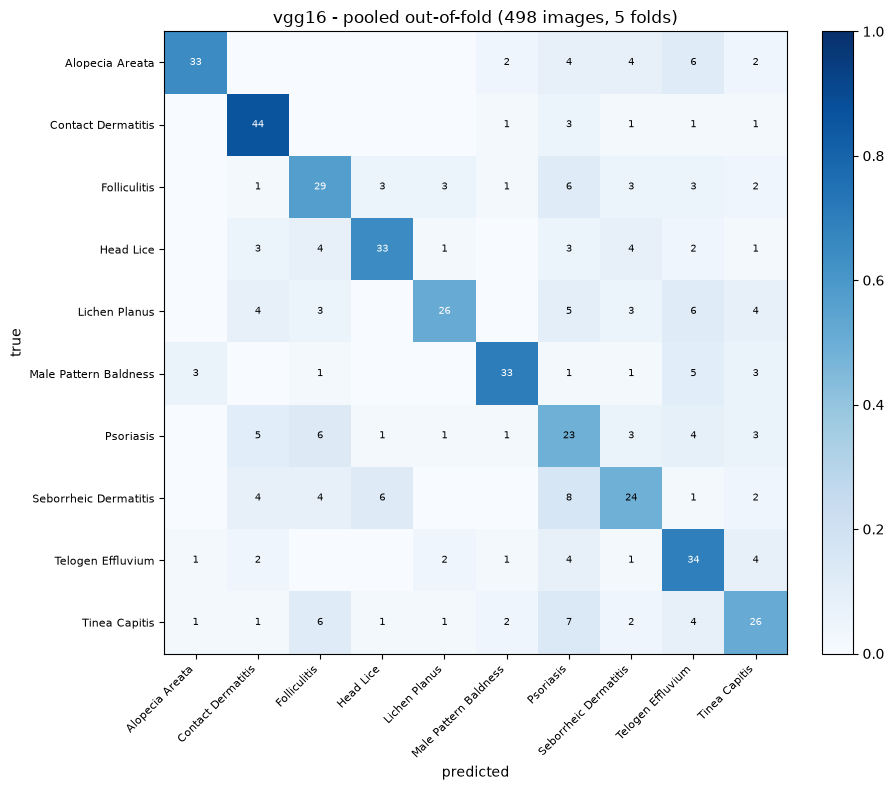


                        precision  recall      f1  support
Alopecia Areata           0.8684  0.6471  0.7416       51
Contact Dermatitis        0.6875  0.8627  0.7652       51
Folliculitis              0.5472  0.5686  0.5577       51
Head Lice                 0.7500  0.6471  0.6947       51
Lichen Planus             0.7647  0.5098  0.6118       51
Male Pattern Baldness     0.8049  0.7021  0.7500       47
Psoriasis                 0.3594  0.4894  0.4144       47
Seborrheic Dermatitis     0.5217  0.4898  0.5053       49
Telogen Effluvium         0.5152  0.6939  0.5913       49
Tinea Capitis             0.5417  0.5098  0.5253       51

Most confused pairs (out-of-fold):
  Seborrheic Dermatitis -> Psoriasis: 8
  Tinea Capitis -> Psoriasis: 7
  Alopecia Areata -> Telogen Effluvium: 6
  Folliculitis -> Psoriasis: 6
  Lichen Planus -> Telogen Effluvium: 6
  Psoriasis -> Folliculitis: 6
  Seborrheic Dermatitis -> Head Lice: 6
  Tinea Capitis -> Folliculitis: 6

Test ensemble of 5 fold models: 

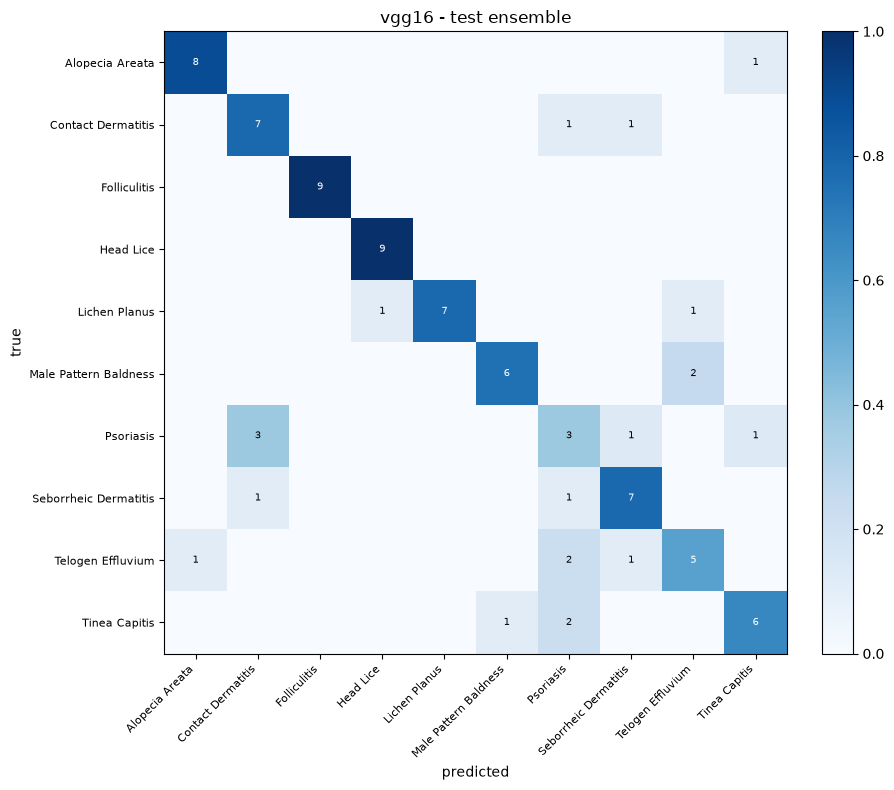

Saved cv_summary.json in /Users/nngoc/Documents/Hair Diseases/Hair-Disease-Research/results/vgg16_cv5_seed42_sub5pct_20261027_122209


In [23]:
cv_runs = [json.load(open(p)) for p in sorted(glob.glob(f"{CV_RUN_DIR}/fold_*/metrics.json"))]
assert cv_runs, "No finished fold yet. Run Cell 37 first."
print(f"Finished folds: {[r['fold'] for r in cv_runs]} of {N_FOLDS}" + ("   (SMOKE TEST)" if CV_SMOKE_TEST else ""))

rows = [{"fold": r["fold"], "phase": r["chosen_phase"], "minutes": r["minutes"],
         **{f"heldout_{m}": r["heldout"][m] for m in CV_METRICS}, "heldout_errors": r["heldout"]["errors"],
         **{f"test_{m}": r["test"][m] for m in CV_METRICS}, "test_errors": r["test"]["errors"]} for r in cv_runs]
cv_fold_df = pd.DataFrame(rows).set_index("fold")
cv_fold_df.to_csv(f"{CV_RUN_DIR}/cv_fold_metrics.csv")
print(cv_fold_df.round(4).to_string())

def cv_mean_std(x):
    x = np.asarray(x, dtype=float); n = len(x)
    s = x.std(ddof=1) if n > 1 else float("nan")
    half = stats.t.ppf(0.975, n - 1) * s / np.sqrt(n) if n > 1 else float("nan")
    return {"mean": float(x.mean()), "std": float(s), "ci95_low": float(x.mean() - half), "ci95_high": float(x.mean() + half)}

cv_summary = {"run_name": CV_RUN_NAME, "model": MODEL_NAME, "n_folds_done": len(cv_runs), "smoke_test": CV_SMOKE_TEST,
              "heldout": {m: cv_mean_std(cv_fold_df[f"heldout_{m}"]) for m in CV_METRICS},
              "test_per_fold_models": {m: cv_mean_std(cv_fold_df[f"test_{m}"]) for m in CV_METRICS}}
print("\nHeld-out (cross-validation) mean +- std:")
for m in CV_METRICS:
    s = cv_summary["heldout"][m]; print(f"  {m:12s} {s['mean']:.4f} +- {s['std']:.4f}   95% CI [{s['ci95_low']:.4f}, {s['ci95_high']:.4f}]")
print("Test set, mean +- std over the fold models:")
for m in CV_METRICS:
    s = cv_summary["test_per_fold_models"][m]; print(f"  {m:12s} {s['mean']:.4f} +- {s['std']:.4f}")

# pooled out-of-fold predictions: every development image predicted once by a model that never saw it
oof = pd.concat([pd.read_csv(f"{CV_RUN_DIR}/fold_{r['fold']}/predictions_heldout.csv") for r in cv_runs], ignore_index=True)
oof.to_csv(f"{CV_RUN_DIR}/oof_predictions.csv", index=False)

def cv_plot_cm(y, pred, path, title):
    m = confusion_matrix(y, pred, labels=range(CV_NUM_CLASSES))
    mn = m / np.maximum(m.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(mn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(CV_NUM_CLASSES)); ax.set_yticks(range(CV_NUM_CLASSES))
    ax.set_xticklabels(cv_classes, rotation=45, ha="right", fontsize=8); ax.set_yticklabels(cv_classes, fontsize=8)
    for i in range(CV_NUM_CLASSES):
        for j in range(CV_NUM_CLASSES):
            if m[i, j]: ax.text(j, i, m[i, j], ha="center", va="center", fontsize=7, color="white" if mn[i, j] > 0.5 else "black")
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
    plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.savefig(path, dpi=140); plt.show()
    return m

cv_cm = cv_plot_cm(oof.true_idx, oof.pred_idx, f"{CV_RUN_DIR}/cv_confusion_matrix.png",
                   f"{MODEL_NAME} - pooled out-of-fold ({len(oof)} images, {len(cv_runs)} folds)")
pr, rc, f1, sup = precision_recall_fscore_support(oof.true_idx, oof.pred_idx, labels=range(CV_NUM_CLASSES), zero_division=0)
cv_per_class = pd.DataFrame({"precision": pr, "recall": rc, "f1": f1, "support": sup}, index=cv_classes)
cv_per_class.to_csv(f"{CV_RUN_DIR}/cv_per_class.csv"); print("\n", cv_per_class.round(4))
pairs = sorted([(cv_classes[i], cv_classes[j], int(cv_cm[i, j])) for i in range(CV_NUM_CLASSES) for j in range(CV_NUM_CLASSES)
                if i != j and cv_cm[i, j]], key=lambda t: -t[2])
pd.DataFrame(pairs, columns=["true", "predicted_as", "count"]).to_csv(f"{CV_RUN_DIR}/cv_confused_pairs.csv", index=False)
print("\nMost confused pairs (out-of-fold):")
for t, p_, n_ in pairs[:8]: print(f"  {t} -> {p_}: {n_}")
cv_summary["pooled_oof"] = cv_metrics(oof.true_idx.values, oof[[f"p_{c}" for c in cv_classes]].values)

# test ensemble of the fold models
P = np.mean([np.load(f"{CV_RUN_DIR}/fold_{r['fold']}/test_probs.npy") for r in cv_runs], axis=0)
P = P / P.sum(axis=1, keepdims=True)
cv_summary["test_ensemble"] = cv_metrics(cv_test_y, P)
e = cv_summary["test_ensemble"]
print(f"\nTest ensemble of {len(cv_runs)} fold models: " + " | ".join(f"{m} {e[m]:.4f}" for m in CV_METRICS) + f" | errors {e['errors']}/{e['n']}")
pd.DataFrame({"file": cv_test.file, "true": [cv_classes[i] for i in cv_test_y], "pred": [cv_classes[i] for i in P.argmax(1)],
              "confidence": P.max(1), **{f"p_{c}": P[:, i] for i, c in enumerate(cv_classes)}}
             ).to_csv(f"{CV_RUN_DIR}/test_ensemble_predictions.csv", index=False)
cv_plot_cm(cv_test_y, P.argmax(1), f"{CV_RUN_DIR}/test_ensemble_confusion_matrix.png", f"{MODEL_NAME} - test ensemble")
json.dump(cv_summary, open(f"{CV_RUN_DIR}/cv_summary.json", "w"), indent=2)
print("Saved cv_summary.json in", CV_RUN_DIR)